Дані, розбиття, ознаки, XGBoost

In [1]:
import os, re, glob, time
import numpy as np, pandas as pd
import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.metrics import average_precision_score, roc_auc_score
import matplotlib.pyplot as plt

os.makedirs("results/figures", exist_ok=True)

def find(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    assert hits, f"не знайшов {name}: перевір Add Input"
    return hits[0]

tr = pd.read_csv(find("train_transaction.csv"))
idn = pd.read_csv(find("train_identity.csv"))
for c in tr.select_dtypes("float64").columns:
    tr[c] = tr[c].astype("float32")
df = tr.merge(idn, on="TransactionID", how="left")
df["has_identity"] = df["TransactionID"].isin(idn["TransactionID"])
df["day"] = (df["TransactionDT"] // 86400).astype(int)
df["week"] = df["day"] // 7
del tr

N = len(df)
TRAIN_W, VAL_W, TEST_W = (0, 17), (18, 21), (22, 26)
inw = lambda r: ((df.week >= r[0]) & (df.week <= r[1])).values
m_tr, m_va, m_te = inw(TRAIN_W), inw(VAL_W), inw(TEST_W)
assert (m_tr | m_va | m_te).all() and not (m_tr & m_va).any() and not (m_va & m_te).any()
assert (m_tr.sum(), m_va.sum(), m_te.sum()) == (431125, 77090, 82325)

ts, tid = df.TransactionDT.values, df.TransactionID.values
order = np.lexsort((tid, ts))
rank = np.empty(N, dtype=np.int64); rank[order] = np.arange(N)
y = df.isFraud.values
assert y.sum() == 20663

X = df.drop(columns=["TransactionID", "isFraud", "TransactionDT", "day", "week"]).copy()
X["hour"] = (df.TransactionDT // 3600) % 24
X["weekday"] = (df.TransactionDT // 86400) % 7
X["has_identity"] = X["has_identity"].astype("int8")
for c in X.select_dtypes(include=["object", "category"]).columns:
    codes, _ = pd.factorize(X[c])
    X[c] = np.where(codes == -1, np.nan, codes).astype("float32")
spw = (y[m_tr] == 0).sum() / (y[m_tr] == 1).sum()

def metrics(y_true, p):
    k = int(y_true.sum()); o = np.argsort(-p)
    top1 = o[: max(1, int(0.01 * len(y_true)))]
    return {"pr_auc": average_precision_score(y_true, p),
            "roc_auc": roc_auc_score(y_true, p),
            "recall@k": y_true[o[:k]].sum() / k,
            "precision@1%": y_true[top1].mean()}

major = int(xgb.__version__.split(".")[0])
DEV = dict(tree_method="hist", device="cuda") if major >= 2 else dict(tree_method="gpu_hist")

def run_xgb_X(Xf, seed):
    m = XGBClassifier(n_estimators=1000, learning_rate=0.1, max_depth=6,
                      subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw,
                      eval_metric="aucpr", early_stopping_rounds=50,
                      random_state=seed, **DEV)
    m.fit(Xf[m_tr], y[m_tr], eval_set=[(Xf[m_va], y[m_va])], verbose=False)
    r = metrics(y[m_te], m.predict_proba(Xf[m_te])[:, 1])
    r.update(seed=seed, best_iter=m.best_iteration, val_aucpr=m.best_score)
    return r

print("готово:", X.shape, "| xgboost", xgb.__version__)

готово: (590540, 434) | xgboost 3.4.1


Мітки сусідів для різних налаштувань + перевірка на витік

In [2]:
KEYS = {"c1": ["card1"], "u2": ["card1", "addr1"],
        "u3": ["card1", "addr1", "P_emaildomain"]}

def label_feats(cols, W_days, DLd):
    """W_days = 0 означає необмежену історію"""
    valid = df[cols].notna().all(axis=1).values; idx = np.flatnonzero(valid)
    nk = np.full(N, np.nan, "float32"); fk = np.full(N, np.nan, "float32")
    for pos in df.loc[valid, cols].groupby(cols, sort=False).indices.values():
        rows = idx[pos]; rows = rows[np.argsort(rank[rows], kind="stable")]
        tt, ff = ts[rows], y[rows]; cs = np.concatenate([[0], np.cumsum(ff)])
        a = np.searchsorted(tt, tt, side="left")
        hi = np.minimum(np.searchsorted(tt, tt - DLd * 86400, side="right"), a)
        lo = np.searchsorted(tt, tt - W_days * 86400, side="left") if W_days else np.zeros_like(hi)
        lo = np.minimum(lo, hi)
        nk[rows] = hi - lo; fk[rows] = cs[hi] - cs[lo]
    return nk, fk

LF = {}
def get_LF(W, DLd):
    if (W, DLd) not in LF:
        d = {}
        for rel, cols in KEYS.items():
            nk, fk = label_feats(cols, W, DLd)
            d[f"{rel}_nk"], d[f"{rel}_fk"] = nk, fk
            d[f"{rel}_rate"] = (fk / np.where(nk > 0, nk, np.nan)).astype("float32")
        LF[(W, DLd)] = pd.DataFrame(d)
    return LF[(W, DLd)]

def check(W, DLd, per_rel=40, seed=0):
    """перерахунок «в лоб» для випадкових рядків: сусіди віком від DLd днів (і не старші за W днів)"""
    L = get_LF(W, DLd); rng = np.random.default_rng(seed); bad = 0
    for rel, cols in KEYS.items():
        cand = np.flatnonzero(df[cols].notna().all(axis=1).values)
        for i in rng.choice(cand, per_rel, replace=False):
            same = np.ones(N, bool)
            for c in cols: same &= (df[c].values == df[c].values[i])
            kn = same & (ts <= ts[i] - DLd * 86400)
            if W: kn &= (ts >= ts[i] - W * 86400)
            if (int(kn.sum()) != int(L[f"{rel}_nk"].values[i]) or
                    int(y[kn].sum()) != int(L[f"{rel}_fk"].values[i])):
                bad += 1
    return bad

t0 = time.time()
for W, DLd in [(30, 7), (0, 7), (30, 14)]:
    b = check(W, DLd)
    print(f"вікно {W or 'необмежене'} дн., затримка {DLd} дн.: розбіжностей {b} | {time.time()-t0:.0f} с", flush=True)
    assert b == 0
print("перевірки на витік пройдено")

вікно 30 дн., затримка 7 дн.: розбіжностей 0 | 4 с
вікно необмежене дн., затримка 7 дн.: розбіжностей 0 | 9 с
вікно 30 дн., затримка 14 дн.: розбіжностей 0 | 13 с
перевірки на витік пройдено


Усі 12 варіантів, 5 seed

In [3]:
ALL = ["c1", "u2", "u3"]
VARS = {
    "без міток":               dict(rels=[],            W=30, dl=7),
    "повна (c1+u2+u3)":        dict(rels=ALL,           W=30, dl=7),
    "лише c1":                 dict(rels=["c1"],        W=30, dl=7),
    "лише u2":                 dict(rels=["u2"],        W=30, dl=7),
    "лише u3":                 dict(rels=["u3"],        W=30, dl=7),
    "без c1 (u2+u3)":          dict(rels=["u2", "u3"],  W=30, dl=7),
    "без u2 (c1+u3)":          dict(rels=["c1", "u3"],  W=30, dl=7),
    "без u3 (c1+u2)":          dict(rels=["c1", "u2"],  W=30, dl=7),
    "без групи V (мітки є)":   dict(rels=ALL,           W=30, dl=7, noV=True),
    "без групи V, без міток":  dict(rels=[],            W=30, dl=7, noV=True),
    "без вікна (W=∞)":         dict(rels=ALL,           W=0,  dl=7),
    "δ=14":                    dict(rels=ALL,           W=30, dl=14),
}
vcols = [c for c in X.columns if re.fullmatch(r"V\d+", c)]
print("V-колонок:", len(vcols))

def make_X(v):
    base = X.drop(columns=vcols) if v.get("noV") else X
    if not v["rels"]: return base
    L = get_LF(v["W"], v["dl"])
    cols = [f"{r}_{k}" for r in v["rels"] for k in ("nk", "fk", "rate")]
    return pd.concat([base, L[cols]], axis=1)

rows = []
for name, v in VARS.items():
    t0 = time.time(); Xf = make_X(v)
    for sd in range(5):
        r = run_xgb_X(Xf, sd); r["variant"] = name; rows.append(r)
    pr = [x["pr_auc"] for x in rows if x["variant"] == name]
    print(f"{name:26s} test PR-AUC {np.mean(pr):.4f} ± {np.std(pr, ddof=1):.4f} | {time.time()-t0:.0f} с", flush=True)
    pd.DataFrame(rows).to_csv("results/ieee_cis_ablations_5seeds.csv", index=False)

V-колонок: 339


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [09:38:54] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


без міток                  test PR-AUC 0.5051 ± 0.0029 | 194 с
повна (c1+u2+u3)           test PR-AUC 0.5954 ± 0.0053 | 144 с
лише c1                    test PR-AUC 0.5382 ± 0.0052 | 171 с
лише u2                    test PR-AUC 0.5778 ± 0.0025 | 155 с
лише u3                    test PR-AUC 0.5784 ± 0.0027 | 149 с
без c1 (u2+u3)             test PR-AUC 0.5957 ± 0.0040 | 153 с
без u2 (c1+u3)             test PR-AUC 0.5859 ± 0.0023 | 154 с
без u3 (c1+u2)             test PR-AUC 0.5753 ± 0.0032 | 143 с
без групи V (мітки є)      test PR-AUC 0.5773 ± 0.0049 | 52 с
без групи V, без міток     test PR-AUC 0.4852 ± 0.0045 | 58 с
без вікна (W=∞)            test PR-AUC 0.5722 ± 0.0051 | 150 с
δ=14                       test PR-AUC 0.5704 ± 0.0037 | 146 с


Підсумкова таблиця й один рисунок

,val PR-AUC,test PR-AUC,test std,Δtest vs повна,std Δtest,Δval vs повна,Recall@k,Precision@1%,"значуще гірше (Δval і Δtest < −0,01)"
variant,,,,,,,,,
без міток,0.555,0.505,0.003,-0.090,0.004,-0.084,0.487,0.876,True
повна (c1+u2+u3),0.640,0.595,0.005,0.000,0.000,0.000,0.561,0.903,False
лише c1,0.587,0.538,0.005,-0.057,0.006,-0.053,0.520,0.882,True
лише u2,0.620,0.578,0.002,-0.018,0.005,-0.020,0.550,0.900,True
лише u3,0.620,0.578,0.003,-0.017,0.005,-0.020,0.550,0.903,True
без c1 (u2+u3),0.642,0.596,0.004,0.000,0.007,0.002,0.562,0.913,False
без u2 (c1+u3),0.630,0.586,0.002,-0.010,0.004,-0.010,0.558,0.907,False
без u3 (c1+u2),0.618,0.575,0.003,-0.020,0.008,-0.022,0.544,0.894,True
без групи V (мітки є),0.628,0.577,0.005,-0.018,0.007,-0.011,0.551,0.893,True


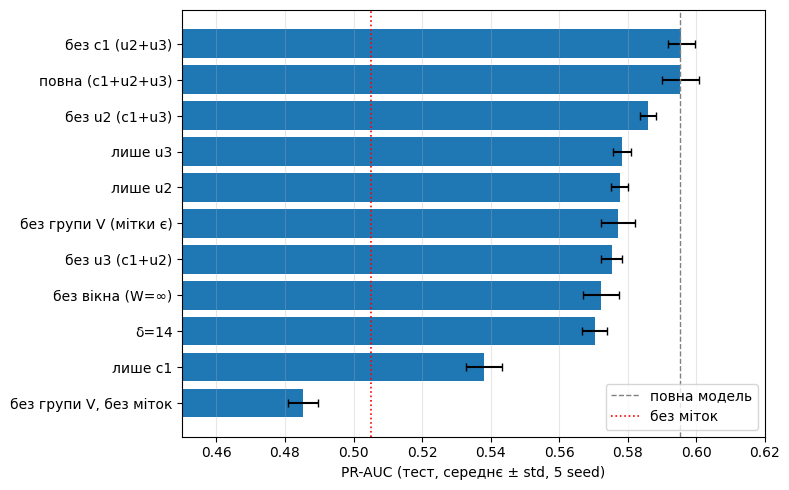

In [4]:
res = pd.DataFrame(rows)
ref = "повна (c1+u2+u3)"
P = lambda col: res.pivot(index="seed", columns="variant", values=col)[list(VARS)]
pt, pv = P("pr_auc"), P("val_aucpr")
dt, dv = pt.sub(pt[ref], axis=0), pv.sub(pv[ref], axis=0)      # парні різниці за seed

summ = pd.DataFrame({
    "val PR-AUC": pv.mean(), "test PR-AUC": pt.mean(), "test std": pt.std(),
    "Δtest vs повна": dt.mean(), "std Δtest": dt.std(), "Δval vs повна": dv.mean(),
    "Recall@k": P("recall@k").mean(), "Precision@1%": P("precision@1%").mean()}).round(3)
summ["значуще гірше (Δval і Δtest < −0,01)"] = (dt.mean() < -0.01) & (dv.mean() < -0.01)
display(summ)
summ.to_csv("results/ieee_cis_ablations_summary.csv")

s = pt.mean().drop("без міток"); e = pt.std().drop("без міток")
s, e = s.sort_values(), e[s.sort_values().index]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(s.index, s.values, xerr=e.values, capsize=3)
ax.axvline(pt[ref].mean(), color="gray", ls="--", lw=1, label="повна модель")
ax.axvline(pt["без міток"].mean(), color="red", ls=":", lw=1.2, label="без міток")
ax.set_xlim(0.45, 0.62); ax.set_xlabel("PR-AUC (тест, середнє ± std, 5 seed)")
ax.legend(loc="lower right"); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.savefig("results/figures/ieee_cis_ablations.png", dpi=200); plt.show()

Точніші ключі

In [5]:
df["D1n"] = (df["D1"] - df["TransactionDT"] / 86400).round()
print("D1 заповнено:", round(df["D1"].notna().mean() * 100, 1), "%")

ALLK = {"u2": ["card1", "addr1"], "u3": ["card1", "addr1", "P_emaildomain"],
        "u4": ["card1", "card2", "card3", "card5", "addr1"],
        "u5": ["card1", "addr1", "P_emaildomain", "D1n"]}
_c = {}
def lab_cols(rel, W=30, dl=7):
    k = (rel, W, dl)
    if k not in _c:
        nk, fk = label_feats(ALLK[rel], W, dl)
        _c[k] = pd.DataFrame({f"{rel}_nk": nk, f"{rel}_fk": fk,
                              f"{rel}_rate": (fk / np.where(nk > 0, nk, np.nan)).astype("float32")})
    return _c[k]

def check_rel(rel, W=30, dl=7, n=60, seed=0):
    cols = ALLK[rel]; L = lab_cols(rel, W, dl); rng = np.random.default_rng(seed); bad = 0
    cand = np.flatnonzero(df[cols].notna().all(axis=1).values)
    for i in rng.choice(cand, n, replace=False):
        same = np.ones(N, bool)
        for c in cols: same &= (df[c].values == df[c].values[i])
        kn = same & (ts <= ts[i] - dl * 86400) & (ts >= ts[i] - W * 86400)
        if (int(kn.sum()) != int(L[f"{rel}_nk"].values[i]) or
                int(y[kn].sum()) != int(L[f"{rel}_fk"].values[i])): bad += 1
    return bad

for rel in ALLK:
    b = check_rel(rel); print(f"{rel}: розбіжностей {b}, охоплення "
          f"{df[ALLK[rel]].notna().all(axis=1).mean()*100:.1f} %", flush=True)
    assert b == 0
print("перевірки на витік пройдено")

VARS2 = {"u2+u3 (база)": ["u2", "u3"], "+u4": ["u2", "u3", "u4"],
         "+u5": ["u2", "u3", "u5"], "+u4+u5": ["u2", "u3", "u4", "u5"]}
rows2 = []
for name, rels in VARS2.items():
    t0 = time.time(); Xf = pd.concat([X] + [lab_cols(r) for r in rels], axis=1)
    for sd in range(5):
        r = run_xgb_X(Xf, sd); r["variant"] = name; rows2.append(r)
    print(name, "готово,", round(time.time() - t0), "с", flush=True)
    pd.DataFrame(rows2).to_csv("results/ieee_cis_keys_round_5seeds.csv", index=False)

r2 = pd.DataFrame(rows2)
pt2 = r2.pivot(index="seed", columns="variant", values="pr_auc")[list(VARS2)]
pv2 = r2.pivot(index="seed", columns="variant", values="val_aucpr")[list(VARS2)]
s2 = pd.DataFrame({"val PR-AUC": pv2.mean(), "test PR-AUC": pt2.mean(), "test std": pt2.std(),
                   "Δval до бази": pv2.sub(pv2["u2+u3 (база)"], axis=0).mean(),
                   "Δtest до бази": pt2.sub(pt2["u2+u3 (база)"], axis=0).mean()}).round(3)
s2["приймаємо (Δval > +0,01)"] = s2["Δval до бази"] > 0.01
display(s2); s2.to_csv("results/ieee_cis_keys_round_summary.csv")

D1 заповнено: 99.8 %
u2: розбіжностей 0, охоплення 88.9 %
u3: розбіжностей 0, охоплення 73.3 %
u4: розбіжностей 0, охоплення 87.1 %
u5: розбіжностей 0, охоплення 73.1 %
перевірки на витік пройдено
u2+u3 (база) готово, 154 с
+u4 готово, 158 с
+u5 готово, 121 с
+u4+u5 готово, 127 с


,val PR-AUC,test PR-AUC,test std,Δval до бази,Δtest до бази,"приймаємо (Δval > +0,01)"
variant,,,,,,
u2+u3 (база),0.642,0.596,0.004,0.000,0.000,False
+u4,0.642,0.595,0.003,0.000,-0.001,False
+u5,0.669,0.631,0.001,0.027,0.035,True
+u4+u5,0.667,0.631,0.002,0.026,0.036,True


Стійкість у часі

без міток готово
+ мітки (u2+u3) готово
+ мітки (u2+u3+u5) готово


модель,частина,"фрод, %",без міток,+ мітки (u2+u3),+ мітки (u2+u3+u5)
тиждень,,,,,
18,val,3.53,0.624,0.688,0.713
19,val,3.46,0.557,0.662,0.687
20,val,3.59,0.492,0.579,0.622
21,val,3.17,0.539,0.649,0.667
22,test,2.85,0.493,0.614,0.650
23,test,3.25,0.466,0.545,0.585
24,test,3.67,0.521,0.604,0.633
25,test,4.18,0.532,0.626,0.658


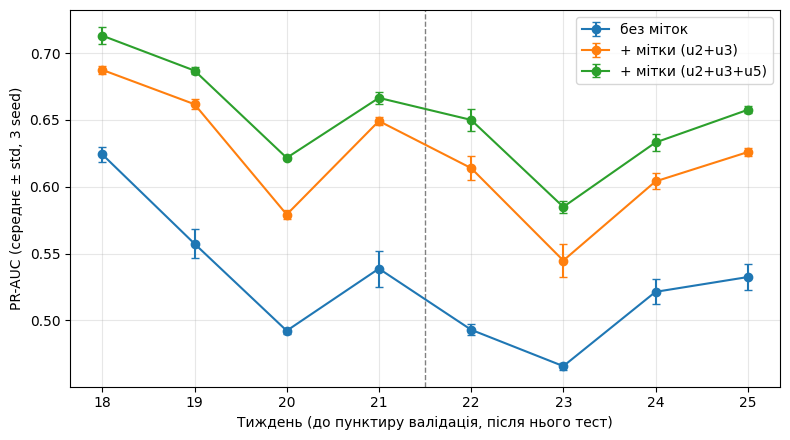

In [7]:
idx_vt = np.flatnonzero(m_va | m_te)
wk = np.minimum(df.week.values[idx_vt], 25)
yy = y[idx_vt]

def fit_pred(Xf, seed):
    m = XGBClassifier(n_estimators=1000, learning_rate=0.1, max_depth=6, subsample=0.8,
                      colsample_bytree=0.8, scale_pos_weight=spw, eval_metric="aucpr",
                      early_stopping_rounds=50, random_state=seed, **DEV)
    m.fit(Xf[m_tr], y[m_tr], eval_set=[(Xf[m_va], y[m_va])], verbose=False)
    return m.predict_proba(Xf.iloc[idx_vt])[:, 1]      # .iloc: вибір рядків за позиціями

MODELS = {
    "без міток": X,
    "+ мітки (u2+u3)": pd.concat([X, lab_cols("u2"), lab_cols("u3")], axis=1),
    "+ мітки (u2+u3+u5)": pd.concat([X, lab_cols("u2"), lab_cols("u3"), lab_cols("u5")], axis=1),
}
rows = []
for name, Xf in MODELS.items():
    for sd in range(3):
        p = fit_pred(Xf, sd)
        for w in range(18, 26):
            m = wk == w
            rows.append({"модель": name, "seed": sd, "тиждень": w, "n": int(m.sum()),
                         "фрод": int(yy[m].sum()), "pr_auc": average_precision_score(yy[m], p[m])})
    print(name, "готово", flush=True)
wkdf = pd.DataFrame(rows)
tab = wkdf.pivot_table(index="тиждень", columns="модель", values="pr_auc", aggfunc="mean")[list(MODELS)]
b0 = wkdf[wkdf["модель"] == "без міток"].groupby("тиждень")[["n", "фрод"]].first()
tab.insert(0, "фрод, %", (b0["фрод"] / b0["n"] * 100).round(2))
tab.insert(0, "частина", ["val" if w <= 21 else "test" for w in tab.index])
display(tab.round(3)); tab.round(4).to_csv("results/ieee_cis_by_week.csv")

fig, ax = plt.subplots(figsize=(8, 4.5))
for name in MODELS:
    g = wkdf[wkdf["модель"] == name].groupby("тиждень")["pr_auc"].agg(["mean", "std"])
    ax.errorbar(g.index, g["mean"], yerr=g["std"], marker="o", capsize=3, label=name)
ax.axvline(21.5, color="gray", ls="--", lw=1)
ax.set_xlabel("Тиждень (до пунктиру валідація, після нього тест)")
ax.set_ylabel("PR-AUC (середнє ± std, 3 seed)")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout()
plt.savefig("results/figures/ieee_cis_pr_auc_by_week.png", dpi=200); plt.show()

Чи несуть міжкартковi ключі сигнал

In [8]:
CROSS = {
    "пристрій (DeviceInfo)":                    ["DeviceInfo"],
    "пристрій + браузер":                       ["DeviceInfo", "id_31"],
    "відбиток (пристрій+ОС+браузер+екран)":     ["DeviceInfo", "id_30", "id_31", "id_33"],
    "адреса + домен + пристрій":                ["addr1", "P_emaildomain", "DeviceInfo"],
    "адреса + домен + D1n (клієнт без картки)": ["addr1", "P_emaildomain", "D1n"],
}
tr_ = m_tr; rows = []
for name, cols in CROSS.items():
    nk, fk = label_feats(cols, 30, 7)
    nks, fks = label_feats(cols + ["card1"], 30, 7)
    has = ~np.isnan(nk)
    nkd = np.where(has, nk - np.nan_to_num(nks), np.nan)
    fkd = np.where(has, fk - np.nan_to_num(fks), np.nan)
    assert np.nanmin(nkd) >= 0 and np.nanmin(fkd) >= 0
    sizes = df[cols].dropna().groupby(cols, sort=False).size()
    a = tr_ & has & (nkd > 0); b = a & (fkd > 0); c = a & (fkd == 0)
    pb = y[b].mean() * 100 if b.sum() else np.nan
    pc = y[c].mean() * 100 if c.sum() else np.nan
    rows.append({"ключ": name,
        "охоплення ключа, %": round((tr_ & has).sum() / tr_.sum() * 100, 1),
        "група p99 / max": f"{int(sizes.quantile(0.99))} / {int(sizes.max())}",
        "є відомі сусіди інших карток, %": round(a.sum() / tr_.sum() * 100, 1),
        "є відомий фрод-сусід іншої картки, %": round(b.sum() / tr_.sum() * 100, 2),
        "P(фрод | фрод-сусід), %": round(pb, 1),
        "P(фрод | сусіди чесні), %": round(pc, 1),
        "відношення": round(pb / pc, 1) if pc and pc > 0 else None})
cross = pd.DataFrame(rows); display(cross)
print("базова частка фроду в train, %:", round(y[tr_].mean() * 100, 2))
cross.to_csv("results/ieee_cis_cross_card_signal.csv", index=False)

,ключ,"охоплення ключа, %",група p99 / max,"є відомі сусіди інших карток, %","є відомий фрод-сусід іншої картки, %","P(фрод | фрод-сусід), %","P(фрод | сусіди чесні), %",відношення
0,пристрій (DeviceInfo),21.7,238 / 47722,19.3,16.47,6.3,9.5,0.7
1,пристрій + браузер,21.7,108 / 16406,17.6,14.12,6.1,6.7,0.9
2,відбиток (пристрій+ОС+браузер+екран),13.3,242 / 2566,10.1,3.30,7.8,2.5,3.1
3,адреса + домен + пристрій,13.4,153 / 1281,9.7,3.04,7.5,2.5,3.0
4,адреса + домен + D1n (клієнт без картки),73.5,49 / 320,12.6,1.38,3.2,2.0,1.6


базова частка фроду в train, %: 3.51


In [9]:
CROSS_KEYS = {"fp": ["DeviceInfo", "id_30", "id_31", "id_33"],
              "ad": ["addr1", "P_emaildomain", "DeviceInfo"]}
_cc = {}
def cross_cols(rel, W=30, dl=7):
    k = (rel, W, dl)
    if k not in _cc:
        cols = CROSS_KEYS[rel]
        nk, fk = label_feats(cols, W, dl)
        nks, fks = label_feats(cols + ["card1"], W, dl)
        has = ~np.isnan(nk)
        nkd = np.where(has, nk - np.nan_to_num(nks), np.nan).astype("float32")
        fkd = np.where(has, fk - np.nan_to_num(fks), np.nan).astype("float32")
        assert np.nanmin(nkd) >= 0 and np.nanmin(fkd) >= 0
        _cc[k] = pd.DataFrame({f"{rel}x_nk": nkd, f"{rel}x_fk": fkd,
                               f"{rel}x_rate": (fkd / np.where(nkd > 0, nkd, np.nan)).astype("float32")})
    return _cc[k]

def check_cross(rel, W=30, dl=7, n=60, seed=0):
    cols = CROSS_KEYS[rel]; L = cross_cols(rel, W, dl)
    rng = np.random.default_rng(seed); bad = 0
    cand = np.flatnonzero(df[cols].notna().all(axis=1).values)
    c1 = df["card1"].values
    for i in rng.choice(cand, n, replace=False):
        same = np.ones(N, bool)
        for c in cols: same &= (df[c].values == df[c].values[i])
        kn = same & (c1 != c1[i]) & (ts <= ts[i] - dl * 86400) & (ts >= ts[i] - W * 86400)
        if (int(kn.sum()) != int(L[f"{rel}x_nk"].values[i]) or
                int(y[kn].sum()) != int(L[f"{rel}x_fk"].values[i])): bad += 1
    return bad

for rel in CROSS_KEYS:
    b = check_cross(rel); print(f"{rel}: розбіжностей {b}", flush=True); assert b == 0
print("перевірки на витік пройдено")

fp_has = df[CROSS_KEYS["fp"]].notna().all(axis=1).values
def run_xgb_sub(Xf, seed):
    m = XGBClassifier(n_estimators=1000, learning_rate=0.1, max_depth=6, subsample=0.8,
                      colsample_bytree=0.8, scale_pos_weight=spw, eval_metric="aucpr",
                      early_stopping_rounds=50, random_state=seed, **DEV)
    m.fit(Xf[m_tr], y[m_tr], eval_set=[(Xf[m_va], y[m_va])], verbose=False)
    p = m.predict_proba(Xf[m_te])[:, 1]
    r = metrics(y[m_te], p)
    sub = fp_has[m_te]
    r["pr_auc_fp_rows"] = average_precision_score(y[m_te][sub], p[sub])
    r.update(seed=seed, val_aucpr=m.best_score)
    return r

BASE = pd.concat([X, lab_cols("u2"), lab_cols("u3"), lab_cols("u5")], axis=1)
VARS3 = {"база (u2+u3+u5)": [], "+fp": ["fp"], "+ad": ["ad"], "+fp+ad": ["fp", "ad"]}
rows3 = []
for name, rels in VARS3.items():
    t0 = time.time()
    Xf = pd.concat([BASE] + [cross_cols(r) for r in rels], axis=1) if rels else BASE
    for sd in range(5):
        r = run_xgb_sub(Xf, sd); r["variant"] = name; rows3.append(r)
    print(name, "готово,", round(time.time() - t0), "с", flush=True)
    pd.DataFrame(rows3).to_csv("results/ieee_cis_cross_card_xgb_5seeds.csv", index=False)

r3 = pd.DataFrame(rows3); b = "база (u2+u3+u5)"
P = lambda c: r3.pivot(index="seed", columns="variant", values=c)[list(VARS3)]
pt, pv, pf = P("pr_auc"), P("val_aucpr"), P("pr_auc_fp_rows")
s3 = pd.DataFrame({"val PR-AUC": pv.mean(), "test PR-AUC": pt.mean(), "test std": pt.std(),
                   "Δval до бази": pv.sub(pv[b], axis=0).mean(),
                   "Δtest до бази": pt.sub(pt[b], axis=0).mean(),
                   "test PR-AUC, рядки з відбитком": pf.mean(),
                   "Δ на рядках з відбитком": pf.sub(pf[b], axis=0).mean()}).round(3)
s3["приймаємо (Δval > +0,01)"] = s3["Δval до бази"] > 0.01
display(s3); s3.to_csv("results/ieee_cis_cross_card_summary.csv")

fp: розбіжностей 0
ad: розбіжностей 0
перевірки на витік пройдено
база (u2+u3+u5) готово, 119 с
+fp готово, 135 с
+ad готово, 136 с
+fp+ad готово, 132 с


,val PR-AUC,test PR-AUC,test std,Δval до бази,Δtest до бази,"test PR-AUC, рядки з відбитком",Δ на рядках з відбитком,"приймаємо (Δval > +0,01)"
variant,,,,,,,,
база (u2+u3+u5),0.669,0.631,0.001,0.000,0.000,0.663,0.000,False
+fp,0.668,0.633,0.002,-0.001,0.001,0.669,0.006,False
+ad,0.669,0.630,0.005,-0.000,-0.001,0.661,-0.003,False
+fp+ad,0.669,0.633,0.003,-0.000,0.002,0.668,0.005,False
